## Práctica 03: Series de Fourier: Magnitud y fase

Sofía Cedeño Vargas, 
Mariana Paulina Vargas

### Crear la señal cuadrada

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la señal
f0 = 1          # Frecuencia fundamental [Hz]
A = 1           # Amplitud
N = 1000        # Número de muestras

# Periodo fundamental
T0 = 1 / f0

# Vector de tiempo: un periodo
t = np.linspace(0, T0, N, endpoint=False)

# Señal cuadrada
x_cuadrada = A * np.where(np.sin(2 * np.pi * f0 * t) >= 0, 1, -1)

print("Frecuencia fundamental:", f0, "Hz")
print("Periodo:", T0, "s")
print("Amplitud:", A)
print("Número de muestras:", N)
print("Primeras 10 muestras:", x_cuadrada[:10])

Frecuencia fundamental: 1 Hz
Periodo: 1.0 s
Amplitud: 1
Número de muestras: 1000
Primeras 10 muestras: [1 1 1 1 1 1 1 1 1 1]


### Construir la señal triangular

In [2]:
# Señal triangular con los mismos parámetros
x_triangular = (2 * A / np.pi) * np.arcsin(
    np.sin(2 * np.pi * f0 * t)
)

print("Frecuencia fundamental:", f0, "Hz")
print("Periodo:", T0, "s")
print("Amplitud máxima:", np.max(x_triangular))
print("Amplitud mínima:", np.min(x_triangular))
print("Número de muestras:", len(x_triangular))
print("Primeras 10 muestras:", x_triangular[:10])

Frecuencia fundamental: 1 Hz
Periodo: 1.0 s
Amplitud máxima: 1.0
Amplitud mínima: -1.0
Número de muestras: 1000
Primeras 10 muestras: [0.    0.004 0.008 0.012 0.016 0.02  0.024 0.028 0.032 0.036]


### Graficar ambas señales

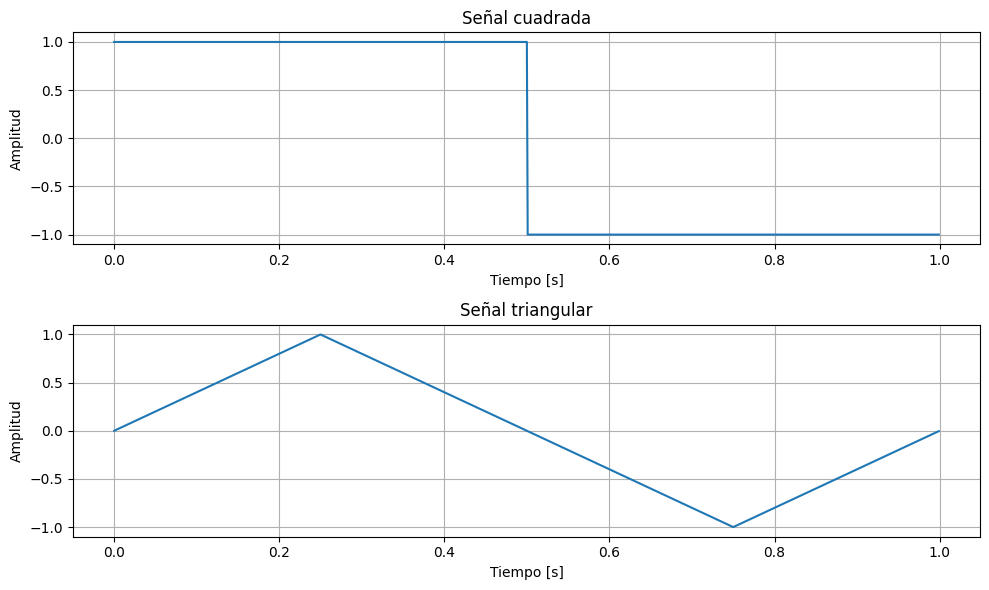

In [3]:
plt.figure(figsize=(10, 6))

# Señal cuadrada
plt.subplot(2, 1, 1)
plt.plot(t, x_cuadrada)
plt.title("Señal cuadrada")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)

# Señal triangular
plt.subplot(2, 1, 2)
plt.plot(t, x_triangular)
plt.title("Señal triangular")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

### Función para calcular los coeficientes de Fourier

In [4]:
def coeficientes_fourier(x):
    """
    Calcula los coeficientes de la serie de Fourier
    exponencial de una señal periódica.
    """
    
    N = len(x)
    
    # FFT normalizada por el número de muestras
    coeficientes = np.fft.fft(x) / N
    
    # Centrar los coeficientes:
    # frecuencias negativas - cero - frecuencias positivas
    coeficientes = np.fft.fftshift(coeficientes)
    
    return coeficientes


print("Función creada correctamente.")

Función creada correctamente.


### Calcular los coeficientes de ambas señales

In [5]:
# Calcular coeficientes de Fourier
C_cuadrada = coeficientes_fourier(x_cuadrada)
C_triangular = coeficientes_fourier(x_triangular)

print("Número de coeficientes señal cuadrada:", len(C_cuadrada))
print("Número de coeficientes señal triangular:", len(C_triangular))

# Coeficiente correspondiente a n = 0
centro = N // 2

print("\nCoeficiente n=0 señal cuadrada:", C_cuadrada[centro])
print("Coeficiente n=0 señal triangular:", C_triangular[centro])

# Primer armónico positivo
print("\nPrimer armónico señal cuadrada:", C_cuadrada[centro + 1])
print("Primer armónico señal triangular:", C_triangular[centro + 1])

Número de coeficientes señal cuadrada: 1000
Número de coeficientes señal triangular: 1000

Coeficiente n=0 señal cuadrada: (0.002+0j)
Coeficiente n=0 señal triangular: (2.555148560345268e-18+0j)

Primer armónico señal cuadrada: (7.993605777301128e-18-0.6366176779711009j)
Primer armónico señal triangular: (-1.9996942520846553e-17-0.4052860679053164j)


### Función para espectros de magnitud y fase

In [6]:
def graficar_espectros(coeficientes, titulo):
    
    N = len(coeficientes)
    
    # Índices de los armónicos
    armonicos = np.arange(-N//2, N//2)
    
    # Magnitud y fase
    magnitud = np.abs(coeficientes)
    fase = np.angle(coeficientes)
    
    plt.figure(figsize=(10, 6))
    
    # Espectro de magnitud
    plt.subplot(2, 1, 1)
    plt.stem(armonicos, magnitud)
    plt.title("Espectro de magnitud - " + titulo)
    plt.xlabel("Armónico n")
    plt.ylabel("|Cₙ|")
    plt.xlim(-20, 20)
    plt.grid(True)
    
    # Espectro de fase
    plt.subplot(2, 1, 2)
    plt.stem(armonicos, fase)
    plt.title("Espectro de fase - " + titulo)
    plt.xlabel("Armónico n")
    plt.ylabel("Fase [rad]")
    plt.xlim(-20, 20)
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


print("Función de espectros creada correctamente.")

Función de espectros creada correctamente.


### Espectros de la señal cuadrada

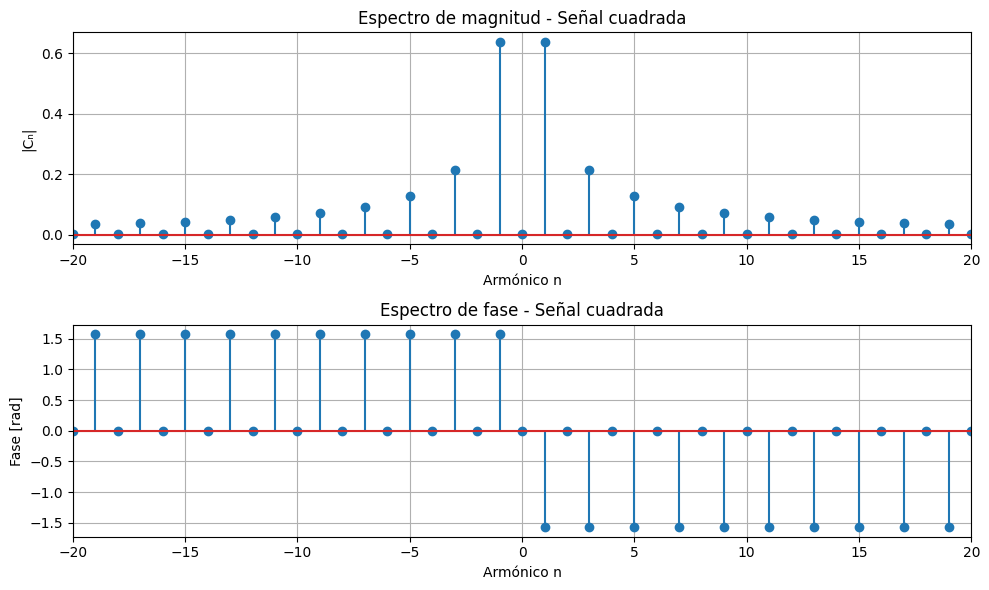

In [7]:
graficar_espectros(C_cuadrada, "Señal cuadrada")

### Señal triangular

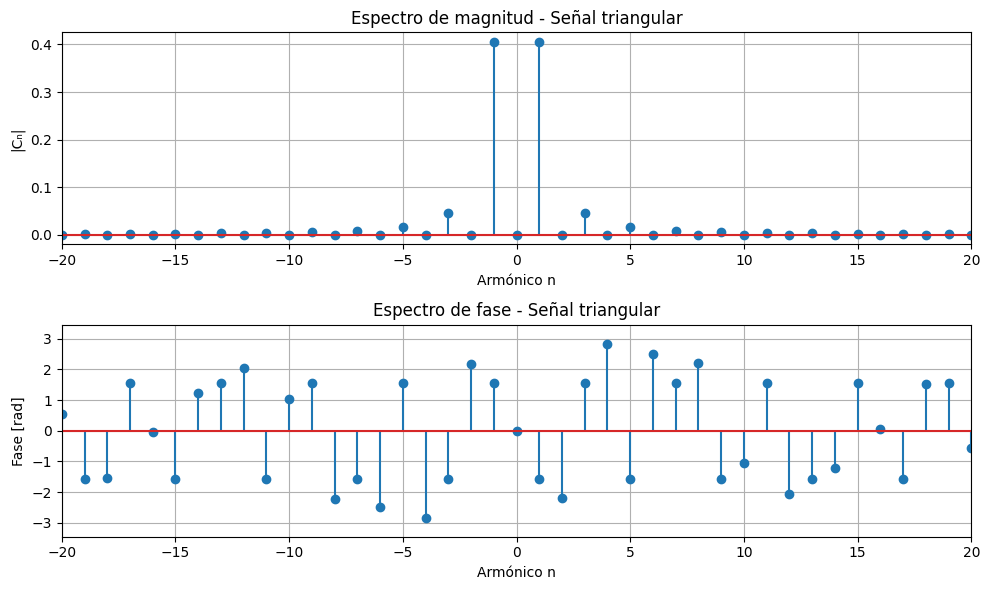

In [8]:
graficar_espectros(C_triangular, "Señal triangular")

### Función de reconstrucción

In [9]:
def reconstruir_senal(coeficientes, t, f0, num_armonicos):
    """
    Reconstruye una señal utilizando sus coeficientes
    de Fourier hasta un número determinado de armónicos.
    """
    
    N = len(coeficientes)
    centro = N // 2
    
    # Componente DC (n = 0)
    reconstruida = np.real(coeficientes[centro]) * np.ones_like(t)
    
    # Sumar armónicos positivos y negativos
    for n in range(1, num_armonicos + 1):
        
        C_pos = coeficientes[centro + n]
        C_neg = coeficientes[centro - n]
        
        reconstruida += np.real(
            C_pos * np.exp(1j * 2 * np.pi * n * f0 * t) +
            C_neg * np.exp(-1j * 2 * np.pi * n * f0 * t)
        )
    
    return reconstruida


print("Función de reconstrucción creada correctamente.")

Función de reconstrucción creada correctamente.


### Reconstrucción de la señal cuadrada con 1 armónico

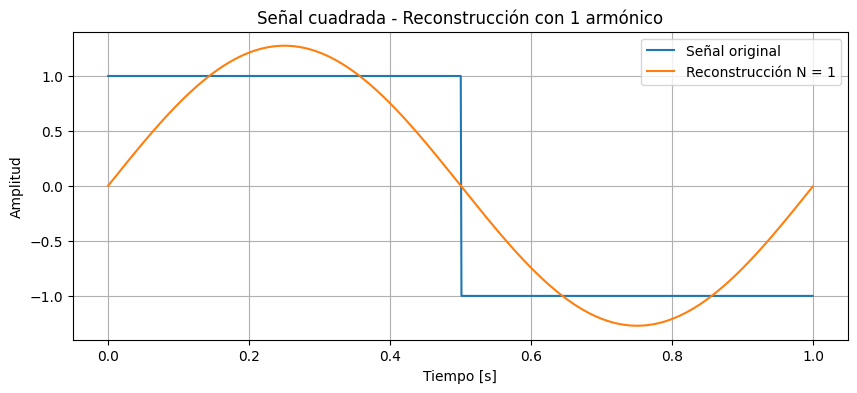

In [10]:
# Reconstrucción de la señal cuadrada con 1 armónico
x_cuadrada_N1 = reconstruir_senal(C_cuadrada, t, f0, 1)

plt.figure(figsize=(10, 4))

plt.plot(t, x_cuadrada, label="Señal original")
plt.plot(t, x_cuadrada_N1, label="Reconstrucción N = 1")

plt.title("Señal cuadrada - Reconstrucción con 1 armónico")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal cuadrada con N = 3

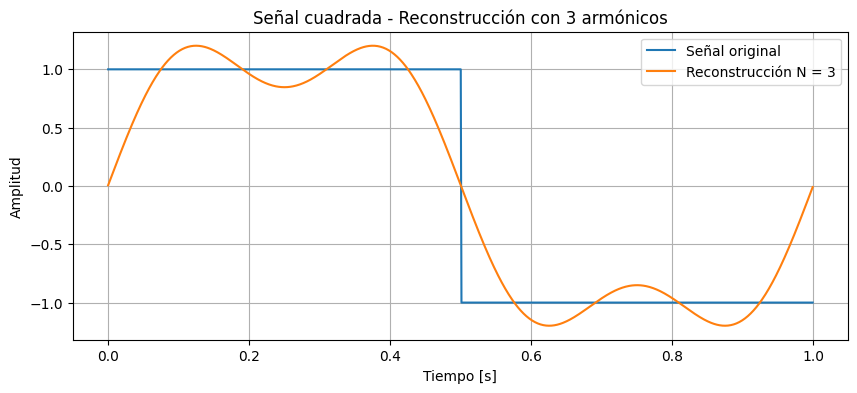

In [11]:
# Reconstrucción de la señal cuadrada con 3 armónicos
x_cuadrada_N3 = reconstruir_senal(C_cuadrada, t, f0, 3)

plt.figure(figsize=(10, 4))

plt.plot(t, x_cuadrada, label="Señal original")
plt.plot(t, x_cuadrada_N3, label="Reconstrucción N = 3")

plt.title("Señal cuadrada - Reconstrucción con 3 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal cuadrada con N = 5

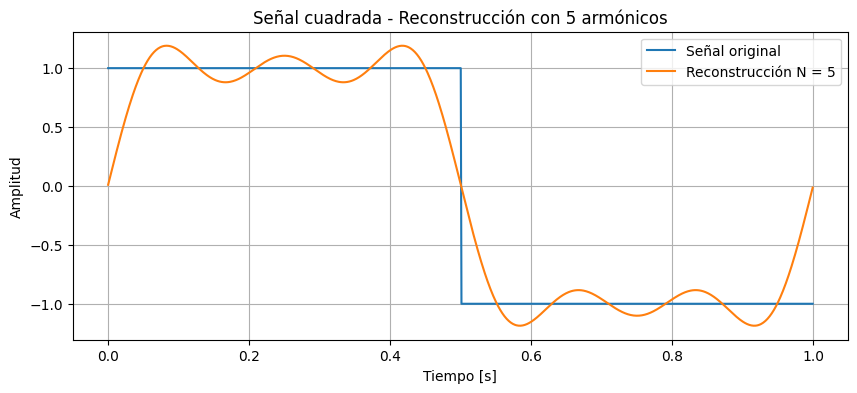

In [12]:
# Reconstrucción de la señal cuadrada con 5 armónicos
x_cuadrada_N5 = reconstruir_senal(C_cuadrada, t, f0, 5)

plt.figure(figsize=(10, 4))

plt.plot(t, x_cuadrada, label="Señal original")
plt.plot(t, x_cuadrada_N5, label="Reconstrucción N = 5")

plt.title("Señal cuadrada - Reconstrucción con 5 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal cuadrada con N = 20

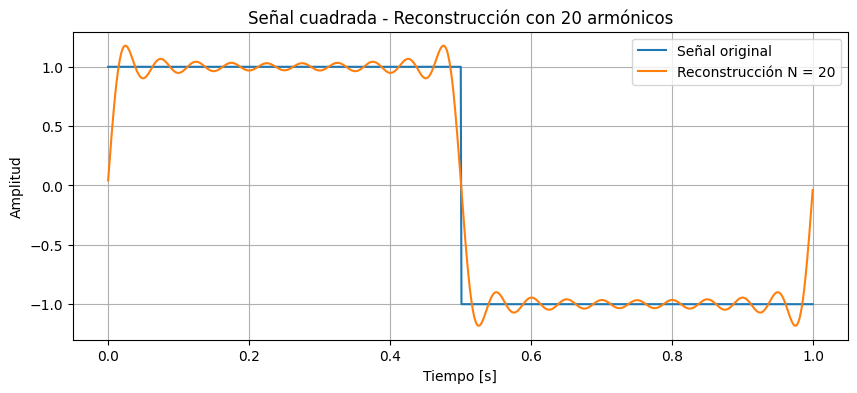

In [13]:
# Reconstrucción de la señal cuadrada con 20 armónicos
x_cuadrada_N20 = reconstruir_senal(C_cuadrada, t, f0, 20)

plt.figure(figsize=(10, 4))

plt.plot(t, x_cuadrada, label="Señal original")
plt.plot(t, x_cuadrada_N20, label="Reconstrucción N = 20")

plt.title("Señal cuadrada - Reconstrucción con 20 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal cuadrada con N = 50

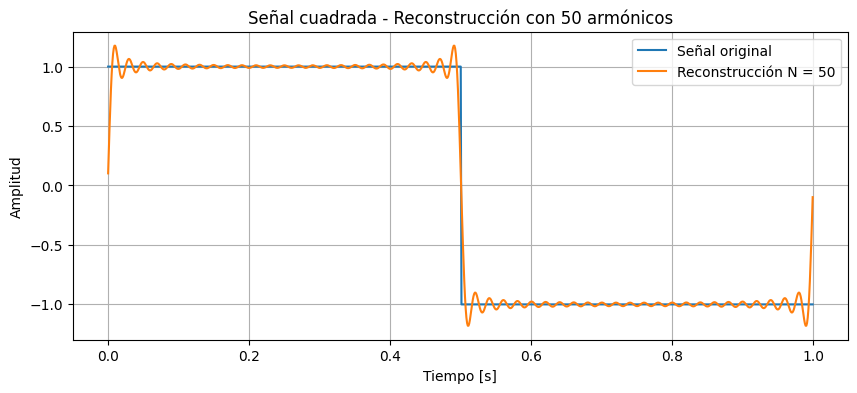

In [14]:
# Reconstrucción de la señal cuadrada con 50 armónicos
x_cuadrada_N50 = reconstruir_senal(C_cuadrada, t, f0, 50)

plt.figure(figsize=(10, 4))

plt.plot(t, x_cuadrada, label="Señal original")
plt.plot(t, x_cuadrada_N50, label="Reconstrucción N = 50")

plt.title("Señal cuadrada - Reconstrucción con 50 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal triangular con N = 1

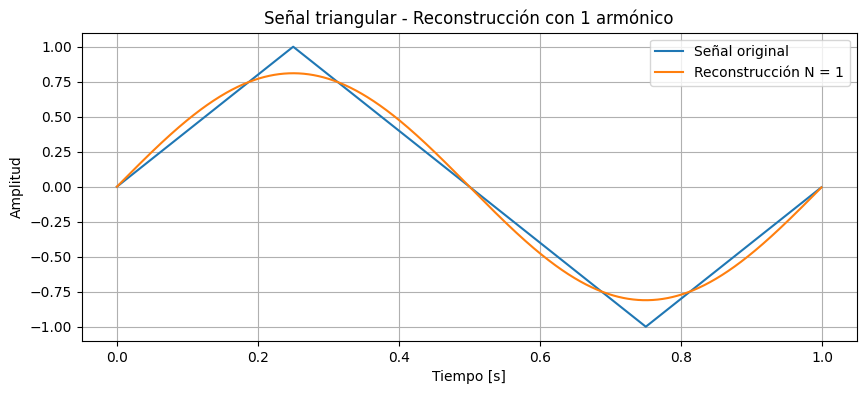

In [15]:
# Reconstrucción de la señal triangular con 1 armónico
x_triangular_N1 = reconstruir_senal(C_triangular, t, f0, 1)

plt.figure(figsize=(10, 4))

plt.plot(t, x_triangular, label="Señal original")
plt.plot(t, x_triangular_N1, label="Reconstrucción N = 1")

plt.title("Señal triangular - Reconstrucción con 1 armónico")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal triangular con N = 3

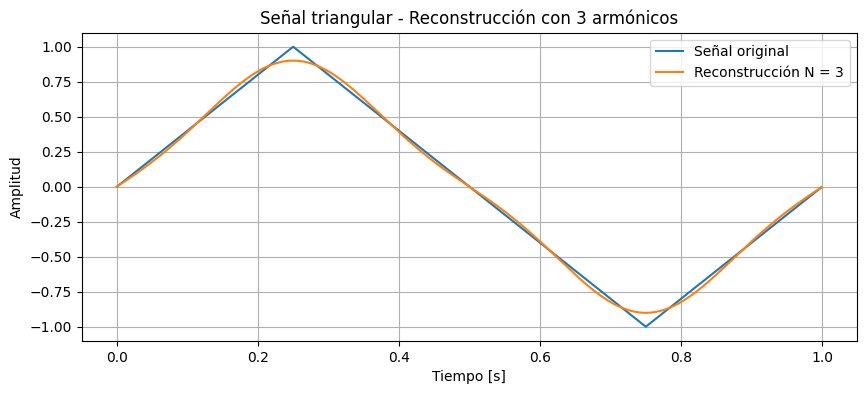

In [16]:
# Reconstrucción de la señal triangular con 3 armónicos
x_triangular_N3 = reconstruir_senal(C_triangular, t, f0, 3)

plt.figure(figsize=(10, 4))

plt.plot(t, x_triangular, label="Señal original")
plt.plot(t, x_triangular_N3, label="Reconstrucción N = 3")

plt.title("Señal triangular - Reconstrucción con 3 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal triangular con N = 5

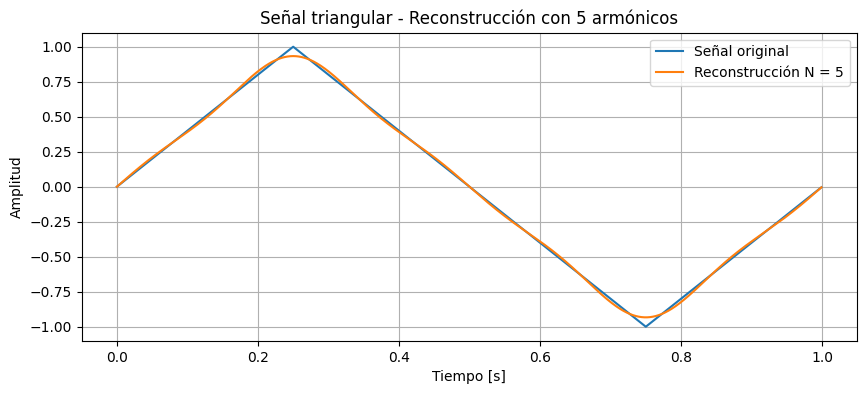

In [17]:
# Reconstrucción de la señal triangular con 5 armónicos
x_triangular_N5 = reconstruir_senal(C_triangular, t, f0, 5)

plt.figure(figsize=(10, 4))

plt.plot(t, x_triangular, label="Señal original")
plt.plot(t, x_triangular_N5, label="Reconstrucción N = 5")

plt.title("Señal triangular - Reconstrucción con 5 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal triangular con N = 20

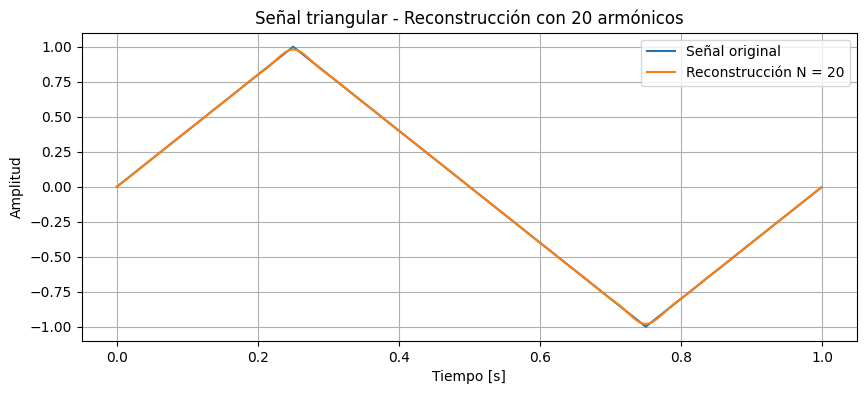

In [18]:
# Reconstrucción de la señal triangular con 20 armónicos
x_triangular_N20 = reconstruir_senal(C_triangular, t, f0, 20)

plt.figure(figsize=(10, 4))

plt.plot(t, x_triangular, label="Señal original")
plt.plot(t, x_triangular_N20, label="Reconstrucción N = 20")

plt.title("Señal triangular - Reconstrucción con 20 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Señal triangular con N = 50

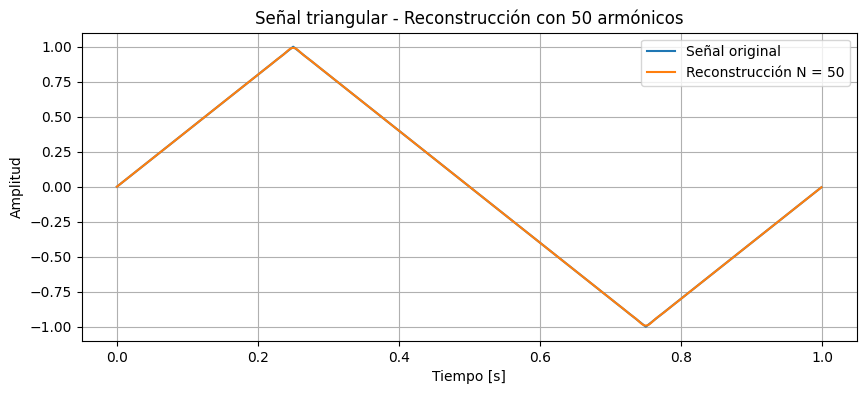

In [19]:
# Reconstrucción de la señal triangular con 50 armónicos
x_triangular_N50 = reconstruir_senal(C_triangular, t, f0, 50)

plt.figure(figsize=(10, 4))

plt.plot(t, x_triangular, label="Señal original")
plt.plot(t, x_triangular_N50, label="Reconstrucción N = 50")

plt.title("Señal triangular - Reconstrucción con 50 armónicos")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)
plt.legend()

plt.show()

### Análisis del fenómeno de Gibbs

En las reconstrucciones de la señal cuadrada se observa el fenómeno de Gibbs, que ocurre cuando una señal con discontinuidades se aproxima utilizando un número finito de armónicos de su serie de Fourier.

Con pocos armónicos, como N = 1, 3 y 5, la reconstrucción presenta oscilaciones considerables y todavía se aleja de la forma cuadrada original. Al aumentar a N = 20 y N = 50, la reconstrucción se aproxima mejor a los valores de la señal original y las oscilaciones se concentran cada vez más cerca de las discontinuidades.

Sin embargo, los sobrepicos alrededor de los cambios bruscos no desaparecen completamente al aumentar el número de armónicos. Este comportamiento corresponde al fenómeno de Gibbs. Por el contrario, en la señal triangular la reconstrucción converge de manera más uniforme porque la señal es continua y no presenta saltos.

In [20]:
import pandas as pd
from pathlib import Path

# Frecuencia de muestreo
FS = 500  # Hz

# Derivaciones del ECG
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF",
         "V1", "V2", "V3", "V4", "V5", "V6"]

# Carpeta donde están los ECG
SIGNALS_DIR = Path("ECGData")

# Archivo seleccionado
FILENAME = "MUSE_20180111_155115_19000.csv"

# Cargar ECG
signal_path = SIGNALS_DIR / FILENAME

ecg_signal = pd.read_csv(
    signal_path,
    header=None,
    names=LEADS
)

print("ECG cargado correctamente.")
print("Número de muestras:", len(ecg_signal))
print("Frecuencia de muestreo:", FS, "Hz")
print("Duración:", len(ecg_signal) / FS, "segundos")

ecg_signal.head()

ECG cargado correctamente.
Número de muestras: 5001
Frecuencia de muestreo: 500 Hz
Duración: 10.002 segundos


,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
0,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
1,-214.72,-229.36,-14.64,224.48,-102.48,-122,614.88,814.96,912.56,126.88,-239.12,-507.52
2,-200.08,-209.84,-9.76,204.96,-97.6,-112.24,605.12,819.84,927.2,165.92,-195.2,-463.6
3,-190.32,-195.2,-4.88,195.2,-92.72,-102.48,600.24,829.6,956.48,204.96,-151.28,-429.44
4,-165.92,-165.92,0,165.92,-82.96,-82.96,590.48,844.24,971.12,239.12,-117.12,-400.16


In [21]:
# Volver a cargar el archivo tomando la primera fila como encabezado
ecg_signal = pd.read_csv(signal_path, header=0)

# Convertir todas las columnas a valores numéricos
ecg_signal = ecg_signal.apply(pd.to_numeric, errors="coerce")

# Eliminar cualquier fila que no contenga datos numéricos válidos
ecg_signal = ecg_signal.dropna().reset_index(drop=True)

print("ECG cargado correctamente.")
print("Número de muestras:", len(ecg_signal))
print("Frecuencia de muestreo:", FS, "Hz")
print("Duración:", len(ecg_signal) / FS, "segundos")

ecg_signal.head()

ECG cargado correctamente.
Número de muestras: 5000
Frecuencia de muestreo: 500 Hz
Duración: 10.0 segundos


,I,II,III,aVR,aVL,aVF,V1,V2,V3,V4,V5,V6
0,-214.72,-229.36,-14.64,224.48,-102.48,-122.00,614.88,814.96,912.56,126.88,-239.12,-507.52
1,-200.08,-209.84,-9.76,204.96,-97.60,-112.24,605.12,819.84,927.20,165.92,-195.20,-463.60
2,-190.32,-195.20,-4.88,195.20,-92.72,-102.48,600.24,829.60,956.48,204.96,-151.28,-429.44
3,-165.92,-165.92,0.00,165.92,-82.96,-82.96,590.48,844.24,971.12,239.12,-117.12,-400.16
4,-161.04,-156.16,4.88,161.04,-82.96,-78.08,585.60,844.24,985.76,273.28,-78.08,-370.88


### Visualizar el ECG sin ruido

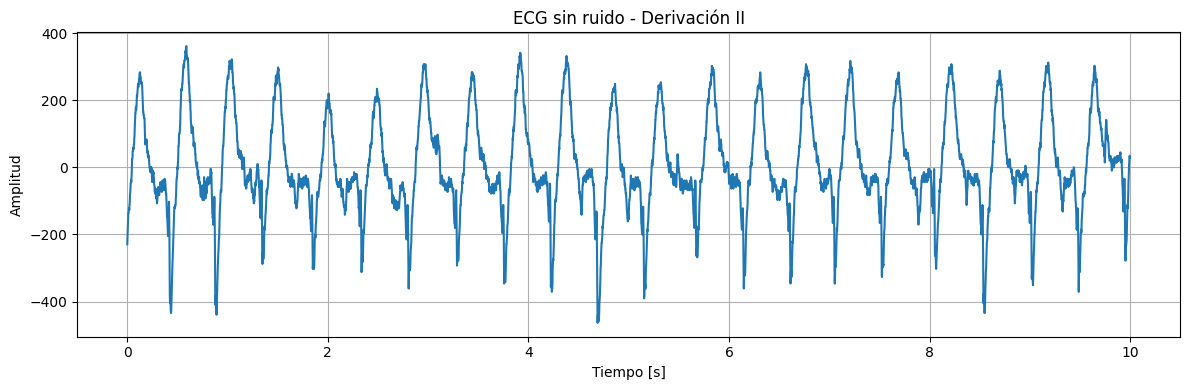

In [22]:
# Seleccionar derivación II
ecg_II = ecg_signal["II"].to_numpy()

# Vector de tiempo
t_ecg = np.arange(len(ecg_II)) / FS

# Graficar ECG
plt.figure(figsize=(12, 4))

plt.plot(t_ecg, ecg_II)

plt.title("ECG sin ruido - Derivación II")
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.grid(True)

plt.tight_layout()
plt.show()

### Calcular y graficar el espectro del ECG

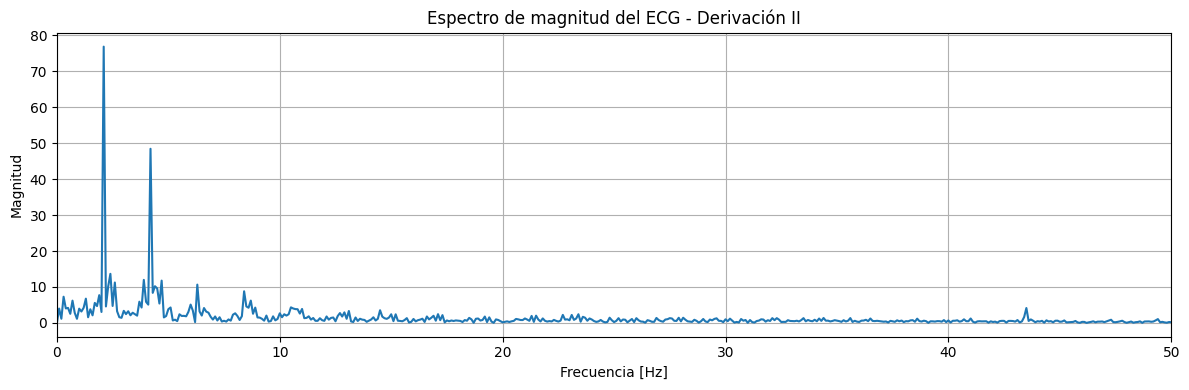

In [23]:
# Eliminar componente DC (valor medio)
ecg_II_centrada = ecg_II - np.mean(ecg_II)

# Número de muestras
N_ecg = len(ecg_II_centrada)

# Transformada de Fourier
fft_ecg = np.fft.rfft(ecg_II_centrada)

# Frecuencias correspondientes
frecuencias = np.fft.rfftfreq(N_ecg, d=1/FS)

# Magnitud normalizada
magnitud_ecg = np.abs(fft_ecg) / N_ecg

# Graficar espectro
plt.figure(figsize=(12, 4))

plt.plot(frecuencias, magnitud_ecg)

plt.title("Espectro de magnitud del ECG - Derivación II")
plt.xlabel("Frecuencia [Hz]")
plt.ylabel("Magnitud")
plt.xlim(0, 50)
plt.grid(True)

plt.tight_layout()
plt.show()

### Identificar las frecuencias dominantes

In [24]:
# Ignorar la componente de 0 Hz
mascara = (frecuencias > 0) & (frecuencias <= 50)

freq_analisis = frecuencias[mascara]
mag_analisis = magnitud_ecg[mascara]

# Obtener los 10 componentes de mayor magnitud
indices = np.argsort(mag_analisis)[-10:][::-1]

print("10 componentes de frecuencia con mayor magnitud:\n")

for i in indices:
    print(
        f"Frecuencia: {freq_analisis[i]:.2f} Hz"
        f" | Magnitud: {mag_analisis[i]:.2f}"
    )

10 componentes de frecuencia con mayor magnitud:

Frecuencia: 2.10 Hz | Magnitud: 76.89
Frecuencia: 4.20 Hz | Magnitud: 48.47
Frecuencia: 2.40 Hz | Magnitud: 13.66
Frecuencia: 3.90 Hz | Magnitud: 11.98
Frecuencia: 4.70 Hz | Magnitud: 11.77
Frecuencia: 2.60 Hz | Magnitud: 11.24
Frecuencia: 6.30 Hz | Magnitud: 10.66
Frecuencia: 4.40 Hz | Magnitud: 10.20
Frecuencia: 2.30 Hz | Magnitud: 10.10
Frecuencia: 4.50 Hz | Magnitud: 9.60


### Interpretación del espectro del ECG

El espectro de la derivación II muestra que la mayor parte de la señal se concentra en frecuencias bajas. En este ECG, los componentes de mayor magnitud se encontraron en 2.10 Hz y 4.20 Hz. El componente de 2.10 Hz está relacionado con la periodicidad dominante de la señal, mientras que 4.20 Hz corresponde a una componente armónica importante de esa periodicidad.

En cuanto a las ondas del ECG, sus rangos de frecuencia se superponen y no es posible asociar cada pico del espectro completo exclusivamente a una onda. De manera aproximada:

- **Onda P:** presenta componentes principalmente entre 5 y 30 Hz y representa la despolarización auricular.
- **Complejo QRS:** presenta un contenido espectral más amplio, aproximadamente entre 5 y 50 Hz. Sus componentes de mayor frecuencia están relacionadas con los cambios rápidos producidos durante la despolarización ventricular.
- **Onda T:** concentra principalmente componentes de baja frecuencia, aproximadamente entre 0 y 10 Hz, debido a que la repolarización ventricular ocurre de manera más lenta.

Por lo tanto, el espectro obtenido muestra un predominio de componentes de baja frecuencia, mientras que las componentes de mayor frecuencia, aunque tienen menor magnitud, contribuyen principalmente a representar los cambios rápidos y los detalles del complejo QRS.